# 03 · Machine learning for $B^\pm\to K^\pm K^+K^-$: weak labels, classifiers, selection and Dalitz plane

**What this notebook is.** The mass fits of notebooks 01 and 02 separate signal from background through the *shape
of the mass spectrum*. Here we use a complementary, data-driven approach: classifiers that tell signal from
background from the **other** variables of the candidates, and then we ask (i) whether a machine-learning selection
changes $A_{\rm raw}$ and (ii) what an *unsupervised* partition of the Dalitz plane shows.

**Scale.** As in the other notebooks this is a guided tour of the method, not the production run: hyperparameter
grids are small and the ensembles smaller than in the report (**report:** values are printed next to ours).

### Map of the notebook

| § | Content | Report (short → cut appendix) |
|---|---|---|
| 1 | Data and **weak labels** | *Weak labels and classifiers*; App. *Weak labels and feature set* |
| 2 | Six classifiers: cross-validated and test AUC, ROC | *Weak labels and classifiers*; App. *Model comparison* |
| 3 | Regularisation (Ridge/Lasso), bias–variance, calibration | *Regularization, bias-variance, uncertainty* |
| 4 | Uncertainty of the score: forest spread, MC dropout, deep ensemble | App. *Uncertainty quantification* |
| 5 | Hyperparameter search and winner's curse [EXTRA] | App. *Hyperparameter optimization* |
| 6 | Use in the measurement: stability of $A_{\rm raw}$, sculpting test | *Effect on the measurement* |
| 7 | $K$-means on the Dalitz plane | *Effect on the measurement*; App. *K-means* |
| 8 | A high-background sample | App. *Stability of $A_{\rm raw}$* |

Parts that go beyond the course are tagged **[EXTRA]**.

## 0 · Setup

In [1]:
import os, time, warnings, copy
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from scipy.stats import norm, chi2, spearmanr
from iminuit import Minuit, cost
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, accuracy_score, silhouette_score, adjusted_rand_score
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans
import tensorflow as tf
from tensorflow import keras

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
M_K = 493.677
LO, HI = 5100.0, 5600.0

## 1 · Data and weak labels

### 1.1 Data
Same preselection and window as in the other notebooks, now with the *features* for the classifiers: for each
of the three tracks the momentum components, the two PID likelihoods and the impact-parameter $\chi^2$ (18 features),
plus two variables of the $B$ candidate (flight distance, vertex $\chi^2$): **20 features, the mass is not one of them**.
We keep a looser PID sample (`ProbK` > 0.3) for the study of §8 and select the nominal one from it.

In [2]:
tracks = (1, 2, 3)
FEATURES = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "IPChi2")] + ["B_FlightDistance", "B_VertexChi2"]
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge", "IPChi2")]
branches += ["B_FlightDistance", "B_VertexChi2"]
frames = []
for pol in ("Down", "Up"):
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        t = f["DecayTree"].arrays(branches, library="pd")
    t["magnet"] = pol.lower()
    frames.append(t)
df = pd.concat(frames, ignore_index=True)
keep = np.ones(len(df), bool)
for i in tracks:
    keep &= ((df[f"H{i}_ProbK"] > 0.3) & (df[f"H{i}_ProbPi"] < 0.5) & ~df[f"H{i}_isMuon"].astype(bool)).to_numpy()
d = df[keep].reset_index(drop=True); del df

def invariant_mass(d, particles):
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"], d["m12"], d["m13"] = invariant_mass(d, (1, 2, 3)), invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"] = d.H1_Charge + d.H2_Charge + d.H3_Charge
d["min_probk"] = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)
d = d[(np.abs(d.q) == 1) & (d.m > LO) & (d.m < HI)].reset_index(drop=True)
data = d[d.min_probk > 0.5].reset_index(drop=True)       # nominal sample
print(f"candidates in the window: nominal {len(data)} (report 19731),  looser ProbK > 0.3: {len(d)} (report 33328)")

candidates in the window: nominal 19731 (report 19731),  looser ProbK > 0.3: 33328 (report 33328)


### 1.2 Mass fit: $\mu$ and $\sigma$ for the labels

A compact version of the nominal fit of notebook 01 (simultaneous fit of $B^+$ and $B^-$, Gaussian signal,
double-exponential background per charge). We need it now for $\mu$ and $\sigma$, and in §6 and §8 to refit the
selected samples. Model and fit are written exactly as in notebook 01.

In [3]:
def gauss_pdf(m, mu, sigma):
    return norm.pdf(m, mu, sigma) / (norm.cdf(HI, mu, sigma) - norm.cdf(LO, mu, sigma))
def exp_pdf(m, lam):
    return lam * np.exp(-lam * (m - LO)) / (1 - np.exp(-lam * (HI - LO)))
def bkg_pdf(m, lam1, lam2, f):
    return f * exp_pdf(m, lam1) + (1 - f) * exp_pdf(m, lam2)

def model_pos(m, N_s, A, mu, sigma, N_b_pos, lam1_pos, lam2_pos, f_pos):
    n_sig = N_s * (1 - A) / 2
    return n_sig + N_b_pos, n_sig * gauss_pdf(m, mu, sigma) + N_b_pos * bkg_pdf(m, lam1_pos, lam2_pos, f_pos)
def model_neg(m, N_s, A, mu, sigma, N_b_neg, lam1_neg, lam2_neg, f_neg):
    n_sig = N_s * (1 + A) / 2
    return n_sig + N_b_neg, n_sig * gauss_pdf(m, mu, sigma) + N_b_neg * bkg_pdf(m, lam1_neg, lam2_neg, f_neg)

def fit_asymmetry(s):
    """Nominal simultaneous fit on a sample s (columns m, q). Returns the Minuit object (A, errors, chi2 via fval)."""
    mp, mn = s.m[s.q > 0].to_numpy(), s.m[s.q < 0].to_numpy()
    nll = cost.ExtendedUnbinnedNLL(mp, model_pos) + cost.ExtendedUnbinnedNLL(mn, model_neg)
    f = Minuit(nll, N_s=0.78 * len(s), A=-0.04, mu=5284.0, sigma=18.0,
               N_b_pos=0.22 * len(mp), lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15,
               N_b_neg=0.22 * len(mn), lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)
    f.limits["A"] = (-1, 1); f.limits["mu"] = (5260, 5310); f.limits["sigma"] = (3, 40)
    f.limits["N_s"] = (0, 2 * len(s))
    for side in ("pos", "neg"):
        f.limits[f"N_b_{side}"] = (0, 2 * len(s))
        f.limits[f"lam1_{side}"] = (1e-5, 0.1); f.limits[f"lam2_{side}"] = (1e-5, 0.1); f.limits[f"f_{side}"] = (0, 1)
    f.migrad(); f.hesse()
    return f

fit_all = fit_asymmetry(data)
MU, SIGMA = fit_all.values["mu"], fit_all.values["sigma"]
A_full, dA_full = fit_all.values["A"], fit_all.errors["A"]
print(f"mu = {MU:.2f} MeV, sigma = {SIGMA:.2f} MeV;  A_raw = {A_full:+.4f} +- {dA_full:.4f}   (report: 5284.39, 18.00, -0.0441 +- 0.0085)")

mu = 5284.38 MeV, sigma = 18.00 MeV;  A_raw = -0.0441 +- 0.0085   (report: 5284.39, 18.00, -0.0441 +- 0.0085)


### 1.3 Weak labels

No candidate carries a true label. We build **weak labels** from the mass spectrum, following the
*classification without labels* idea (CWoLa): a classifier that separates two samples with *different signal
fractions* — here the window under the peak (mostly signal) and the far sidebands (mostly background) — is, by the
Neyman–Pearson lemma, also the optimal signal/background classifier, **provided the features carry no information on
the mass**. This is why the mass is not a feature.

* signal-like: $|m-\mu|<2\sigma$; background-like: $m\in[5150,\mu-4\sigma]\cup[\mu+4\sigma,5600]$ MeV;
* the gaps $2$–$4\sigma$ and the region below 5150 MeV (partially reconstructed decays, not representative of the
  background under the peak) stay unlabelled.

signal-like 15132, background-like 1939   (report: 15130 and 1940; ratio 0.128)


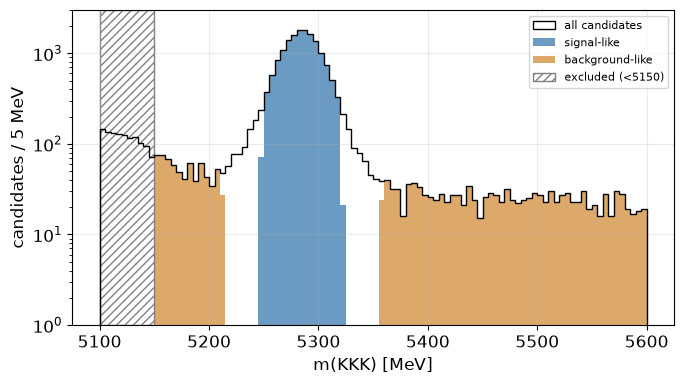

In [4]:
m = data.m.to_numpy()
is_sig = np.abs(m - MU) < 2 * SIGMA
is_bkg = ((m >= 5150) & (m < MU - 4 * SIGMA)) | ((m > MU + 4 * SIGMA) & (m <= HI))
labeled = data[is_sig | is_bkg].copy()
labeled["y"] = is_sig[is_sig | is_bkg].astype(int)
print(f"signal-like {int(labeled.y.sum())}, background-like {int((labeled.y == 0).sum())}   (report: 15130 and 1940; ratio 0.128)")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(LO, HI + 1, 5)
ax.hist(m, bins, histtype="step", color="k", label="all candidates")
ax.hist(m[is_sig], bins, color=C["signal"], alpha=0.8, label="signal-like")
ax.hist(m[is_bkg], bins, color="#d9a05b", alpha=0.9, label="background-like")
ax.axvspan(LO, 5150, facecolor="none", hatch="////", edgecolor="0.5", label="excluded (<5150)")
ax.set(yscale="log", xlabel="m(KKK) [MeV]", ylabel="candidates / 5 MeV", ylim=(1, 3e3)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Train / validation / test split** (stratified 60/20/20) with the standardisation fitted on the training set only.
The classes are imbalanced (0.128): every model uses `balanced` class weights $w_c=N/(2N_c)$.

In [5]:
X, y = labeled[FEATURES].to_numpy(), labeled.y.to_numpy()
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_val, Xs_test = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)
w = {c: len(y_train) / (2 * np.sum(y_train == c)) for c in (0, 1)}                  # balanced class weights
sw_train = np.where(y_train == 1, w[1], w[0])
print(f"train/val/test = {len(y_train)}/{len(y_val)}/{len(y_test)};  class weights: {w[0]:.2f} (background), {w[1]:.2f} (signal)")

train/val/test = 10242/3414/3415;  class weights: 4.40 (background), 0.56 (signal)


## 2 · Six classifiers

Logistic regression with $L_2$ (Ridge) and $L_1$ (Lasso) penalty, a decision tree, a random forest, gradient boosting
and a feed-forward neural network (FFNN). The ranking metric is the **AUC** (area under the ROC curve): the reference
model is chosen on the 5-fold **cross-validated** AUC of the training set, not on the test set; the test AUC is quoted
with a bootstrap uncertainty.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), True),
    "Logistic Regression (L1)": (LogisticRegression(penalty="l1", solver="liblinear", C=0.1, class_weight="balanced", max_iter=2000), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, class_weight="balanced", random_state=SEED), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20, class_weight="balanced",
                                             random_state=SEED, n_jobs=-1), False),
    "Gradient Boosting": (GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED), False),
}
cv_auc, fitted = {}, {}
for name, (mdl, scaled) in models.items():
    Xtr = Xs_train if scaled else X_train
    if name == "Gradient Boosting":
        sc = np.array([roc_auc_score(y_train[te], GradientBoostingClassifier(**mdl.get_params()).fit(
            Xtr[tr], y_train[tr], sample_weight=sw_train[tr]).predict_proba(Xtr[te])[:, 1]) for tr, te in cv.split(Xtr, y_train)])
        mdl.fit(Xtr, y_train, sample_weight=sw_train)
    else:
        sc = cross_val_score(mdl, Xtr, y_train, cv=cv, scoring="roc_auc")
        mdl.fit(Xtr, y_train)
    cv_auc[name] = (sc.mean(), sc.std()); fitted[name] = (mdl, scaled)
    print(f"{name:26s} CV AUC = {sc.mean():.4f} +- {sc.std():.4f}")

Logistic Regression        CV AUC = 0.7802 +- 0.0072


Logistic Regression (L1)   CV AUC = 0.7804 +- 0.0073


Decision Tree              CV AUC = 0.8241 +- 0.0111


Random Forest              CV AUC = 0.8697 +- 0.0139


Gradient Boosting          CV AUC = 0.8698 +- 0.0144


**FFNN.** Fully connected network, ReLU activations, dropout, sigmoid output, binary cross-entropy, Adam,
early stopping on the validation AUC, class weights.

model                       test AUC  (boot sd)   Brier


Logistic Regression           0.7773     0.0128   0.191


Logistic Regression (L1)      0.7767     0.0131   0.192


Decision Tree                 0.8247     0.0127   0.132


Random Forest                 0.8660     0.0119   0.120


Gradient Boosting             0.8721     0.0112   0.112


FFNN                          0.8582     0.0114   0.139
report: tree ensembles and FFNN 0.857-0.864 (indistinguishable, test-set uncertainty 0.012), linear models ~0.77, single tree ~0.82; reference = gradient boosting


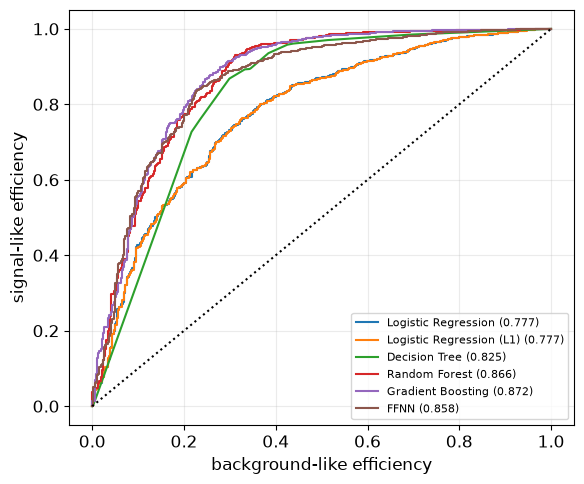

In [7]:
def build_ffnn(layers=(32, 16), dropout=0.2, lr=1e-3, seed=0):
    keras.utils.set_random_seed(seed)
    net = [keras.layers.Input(shape=(Xs_train.shape[1],))]
    for u in layers:
        net += [keras.layers.Dense(u, activation="relu"), keras.layers.Dropout(dropout)]
    net += [keras.layers.Dense(1, activation="sigmoid")]
    mdl = keras.Sequential(net)
    mdl.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return mdl

def train_ffnn(Xtr, ytr, Xva, yva, seed=0, epochs=40, **kw):
    mdl = build_ffnn(seed=seed, **kw)
    es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True)
    mdl.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=256, class_weight=w, callbacks=[es], verbose=0)
    return mdl

ffnn = train_ffnn(Xs_train, y_train, Xs_val, y_val, seed=0)

def predict(name, X_raw, X_scaled):
    if name == "FFNN":
        return ffnn.predict(X_scaled, verbose=0).ravel()
    mdl, scaled = fitted[name]
    return mdl.predict_proba(X_scaled if scaled else X_raw)[:, 1]

order = list(models) + ["FFNN"]
scores = {n: predict(n, X_test, Xs_test) for n in order}

def bootstrap_sd(y_, s_, n=300):
    out = []
    for _ in range(n):
        i = np.random.randint(0, len(y_), len(y_))
        if y_[i].min() != y_[i].max():
            out.append(roc_auc_score(y_[i], s_[i]))
    return np.std(out)

print(f"{'model':26s} {'test AUC':>9s} {'(boot sd)':>10s} {'Brier':>7s}")
for n in order:
    print(f"{n:26s} {roc_auc_score(y_test, scores[n]):9.4f} {bootstrap_sd(y_test, scores[n]):10.4f} {brier_score_loss(y_test, scores[n]):7.3f}")
print("report: tree ensembles and FFNN 0.857-0.864 (indistinguishable, test-set uncertainty 0.012), "
      "linear models ~0.77, single tree ~0.82; reference = gradient boosting")

fig, ax = plt.subplots(figsize=(6, 5))
for n in order:
    fpr, tpr, _ = roc_curve(y_test, scores[n]); ax.plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, scores[n]):.3f})")
ax.plot([0, 1], [0, 1], "k:")
ax.set(xlabel="background-like efficiency", ylabel="signal-like efficiency"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Which features matter** [EXTRA]. The Gini importance of the forest and the magnitude of the Lasso coefficient (on
standardised features) rank the features in two different ways; their rank correlation (Spearman) says how much a
non-linear and a linear model agree.

In [8]:
imp = fitted["Random Forest"][0].feature_importances_
coef = np.abs(fitted["Logistic Regression (L1)"][0].coef_.ravel())
rho = spearmanr(imp, coef)
print(f"Spearman(RF importance, |Lasso coef|) = {rho.correlation:.2f}   (report: 0.42)")
top = np.argsort(-imp)[:5]
print("top 5 by forest importance:", [FEATURES[i] for i in top], "   (report: the two B variables are in the top five)")
print("coefficients set to zero by the Lasso:", int(np.sum(coef == 0)), "of", len(coef))

Spearman(RF importance, |Lasso coef|) = 0.38   (report: 0.42)
top 5 by forest importance: ['H2_IPChi2', 'H1_IPChi2', 'H3_IPChi2', 'B_FlightDistance', 'B_VertexChi2']    (report: the two B variables are in the top five)
coefficients set to zero by the Lasso: 3 of 20


## 3 · Regularisation, bias–variance and calibration

**Ridge and Lasso.** The strength $C=1/\alpha$ of the penalty of the logistic regression is scanned on a logarithmic
grid and chosen on the cross-validated AUC. If the AUC is flat over a wide range the model is not limited by variance
but by the form of its decision boundary (a *linear* boundary).

best L1: C = 0.139, AUC = 0.7804;  best L2: C = 100, AUC = 0.7802   (report: both 0.7686)


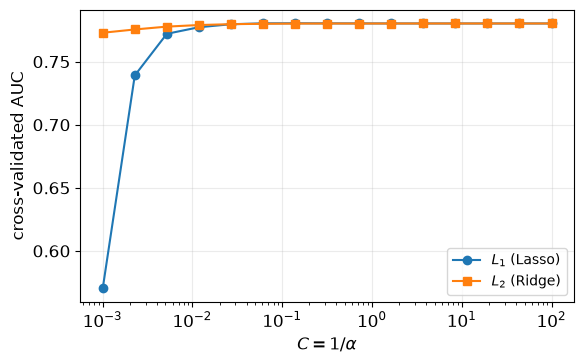

In [9]:
C_grid = np.logspace(-3, 2, 15)
auc_l1 = [cross_val_score(LogisticRegression(penalty="l1", solver="liblinear", C=c, class_weight="balanced", max_iter=2000),
                          Xs_train, y_train, cv=cv, scoring="roc_auc").mean() for c in C_grid]
auc_l2 = [cross_val_score(LogisticRegression(penalty="l2", C=c, class_weight="balanced", max_iter=2000),
                          Xs_train, y_train, cv=cv, scoring="roc_auc").mean() for c in C_grid]
print(f"best L1: C = {C_grid[np.argmax(auc_l1)]:.3g}, AUC = {max(auc_l1):.4f};  best L2: C = {C_grid[np.argmax(auc_l2)]:.3g}, "
      f"AUC = {max(auc_l2):.4f}   (report: both 0.7686)")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(C_grid, auc_l1, "o-", label="$L_1$ (Lasso)"); ax.plot(C_grid, auc_l2, "s-", label="$L_2$ (Ridge)")
ax.set(xscale="log", xlabel="$C=1/\\alpha$", ylabel="cross-validated AUC"); ax.legend()
plt.tight_layout(); plt.show()

**Bias–variance.** The complexity of gradient boosting grows with the number of stages. Evaluating the model after
each stage on the training and on the test set, a growing gap between the two curves is **variance** (overfitting);
a common plateau at a low value is **bias**.

train-test AUC gap: 0.017 at 20 stages, 0.082 at 300   (report: 0.018 and 0.084)
test AUC at 150 stages 0.8717, at 300 stages 0.8703   (report: plateau 0.865 beyond ~150 stages)


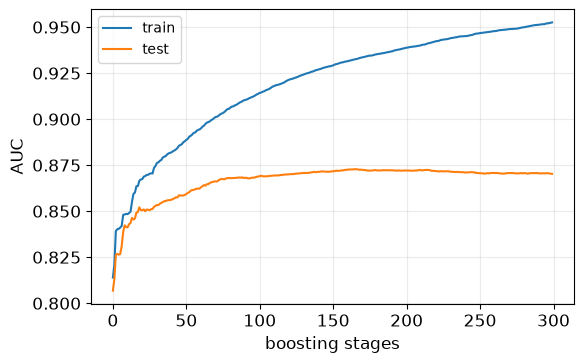

In [10]:
gbm = GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=SEED)
gbm.fit(X_train, y_train, sample_weight=sw_train)
auc_tr = [roc_auc_score(y_train, p[:, 1]) for p in gbm.staged_predict_proba(X_train)]
auc_te = [roc_auc_score(y_test, p[:, 1]) for p in gbm.staged_predict_proba(X_test)]
print(f"train-test AUC gap: {auc_tr[19] - auc_te[19]:.3f} at 20 stages, {auc_tr[-1] - auc_te[-1]:.3f} at 300   (report: 0.018 and 0.084)")
print(f"test AUC at 150 stages {auc_te[149]:.4f}, at 300 stages {auc_te[-1]:.4f}   (report: plateau 0.865 beyond ~150 stages)")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(auc_tr, label="train"); ax.plot(auc_te, label="test"); ax.set(xlabel="boosting stages", ylabel="AUC"); ax.legend()
plt.tight_layout(); plt.show()

**Calibration** [EXTRA]. A score is a probability only if among the candidates with score $\approx p$ a fraction $p$
is signal-like. Class weights *bias* the probabilities: they converge to $\tilde p=w_sp/[w_sp+w_b(1-p)]$ instead of
$p$. An isotonic recalibration on held-out folds corrects it without changing the ranking (so the AUC does not
change). We measure it with the Brier score $\langle(s-y)^2\rangle$.

Brier score of the forest: raw 0.120 -> isotonic 0.061   (report: 0.122 -> 0.062)
AUC raw 0.8660, recalibrated 0.8632


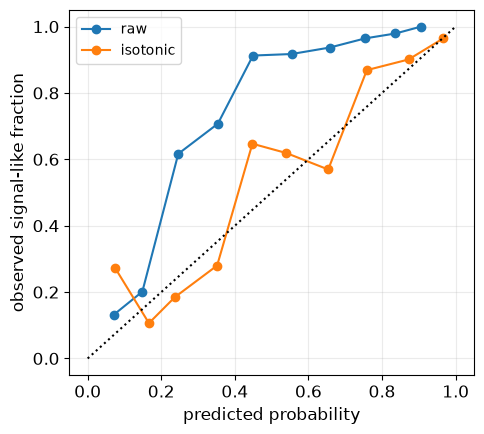

In [11]:
rf_raw = scores["Random Forest"]
cal = CalibratedClassifierCV(RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20,
                             class_weight="balanced", random_state=SEED, n_jobs=-1), method="isotonic", cv=5).fit(X_train, y_train)
rf_cal = cal.predict_proba(X_test)[:, 1]
print(f"Brier score of the forest: raw {brier_score_loss(y_test, rf_raw):.3f} -> isotonic {brier_score_loss(y_test, rf_cal):.3f}   (report: 0.122 -> 0.062)")
print(f"AUC raw {roc_auc_score(y_test, rf_raw):.4f}, recalibrated {roc_auc_score(y_test, rf_cal):.4f}")
fig, ax = plt.subplots(figsize=(5, 4.5))
for s_, lab in ((rf_raw, "raw"), (rf_cal, "isotonic")):
    obs, pred = calibration_curve(y_test, s_, n_bins=10)
    ax.plot(pred, obs, "o-", label=lab)
ax.plot([0, 1], [0, 1], "k:"); ax.set(xlabel="predicted probability", ylabel="observed signal-like fraction"); ax.legend()
plt.tight_layout(); plt.show()

## 4 · Uncertainty of the score

A classifier output comes with an uncertainty. Three estimators, on the test set:

* **Random forest**: standard deviation of the predictions of the individual trees;
* **MC dropout**: the FFNN with dropout *kept active* at prediction time, many stochastic forward passes;
* **deep ensemble**: several FFNNs trained from different random seeds.

They measure different sources of variability. The dependence of the forest spread on the size of the training set
(25 %, 50 %, 100 %) separates the *epistemic* part, which shrinks with more data, from the *aleatoric* part (the
irreducible overlap of the two classes, largest for scores around 0.5).

*Report:* 300 trees, 300 passes, 10 networks. Here 100 passes and 5 networks.

mean per-candidate uncertainty: forest 0.181, MC dropout 0.094, deep ensemble 0.042   (report: 0.178, 0.095, 0.050)
Spearman correlations: forest-MC dropout 0.55, forest-ensemble 0.36, MC dropout-ensemble 0.44
  forest spread with  25% of the training set: 0.221   (report: 0.220, 0.204, 0.179)


  forest spread with  50% of the training set: 0.201   (report: 0.220, 0.204, 0.179)


  forest spread with 100% of the training set: 0.181   (report: 0.220, 0.204, 0.179)


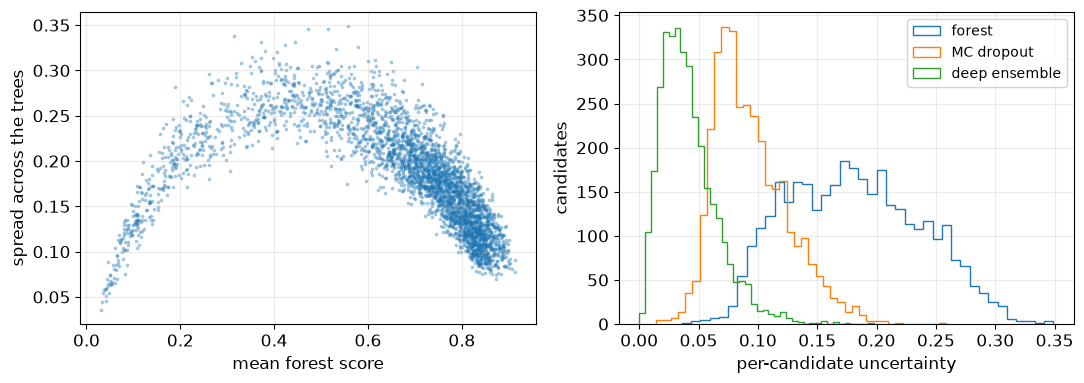

In [12]:
rf = fitted["Random Forest"][0]
tree_preds = np.stack([t.predict_proba(X_test)[:, 1] for t in rf.estimators_])      # (trees, candidates)
unc_rf = tree_preds.std(axis=0)

xt = tf.constant(Xs_test, dtype=tf.float32)
mc = np.stack([ffnn(xt, training=True).numpy().ravel() for _ in range(100)])        # dropout active
unc_mc = mc.std(axis=0)

nets = [ffnn] + [train_ffnn(Xs_train, y_train, Xs_val, y_val, seed=s) for s in range(1, 5)]
unc_de = np.stack([n.predict(Xs_test, verbose=0).ravel() for n in nets]).std(axis=0)

print(f"mean per-candidate uncertainty: forest {unc_rf.mean():.3f}, MC dropout {unc_mc.mean():.3f}, deep ensemble {unc_de.mean():.3f}"
      "   (report: 0.178, 0.095, 0.050)")
print("Spearman correlations: forest-MC dropout {:.2f}, forest-ensemble {:.2f}, MC dropout-ensemble {:.2f}".format(
    spearmanr(unc_rf, unc_mc).correlation, spearmanr(unc_rf, unc_de).correlation, spearmanr(unc_mc, unc_de).correlation))

for frac in (0.25, 0.5, 1.0):
    idx = np.random.choice(len(y_train), int(frac * len(y_train)), replace=False)
    r_ = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=20, class_weight="balanced",
                                random_state=SEED, n_jobs=-1).fit(X_train[idx], y_train[idx])
    sp = np.stack([t.predict_proba(X_test)[:, 1] for t in r_.estimators_]).std(axis=0)
    print(f"  forest spread with {int(100 * frac):3d}% of the training set: {sp.mean():.3f}   (report: 0.220, 0.204, 0.179)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mean_score = tree_preds.mean(axis=0)
ax[0].scatter(mean_score, unc_rf, s=3, alpha=0.3); ax[0].set(xlabel="mean forest score", ylabel="spread across the trees")
for u, lab in ((unc_rf, "forest"), (unc_mc, "MC dropout"), (unc_de, "deep ensemble")):
    ax[1].hist(u, bins=40, histtype="step", label=lab)
ax[1].set(xlabel="per-candidate uncertainty", ylabel="candidates"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5 · Hyperparameter search and the winner's curse [EXTRA]

Do better hyperparameters help? We scan small grids with cross-validation and compare the *test* AUC of the best
configuration with that of the default. Two warnings: the cross-validated maximum is an *optimistic* estimate of the
performance (the *winner's curse*: the best of many noisy values is biased upward), and the gain must be compared
with the uncertainty of the test AUC ($\approx0.012$ here).

*Report:* 120 + 100 + 168 configurations, 5-fold CV repeated 10 times. Here 12 + 12 and 3-fold.

In [13]:
gs_rf = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                     {"n_estimators": [100, 300], "max_depth": [4, 8, None], "min_samples_leaf": [5, 20]},
                     cv=3, scoring="roc_auc").fit(X_train, y_train)
gs_gb = GridSearchCV(GradientBoostingClassifier(random_state=SEED),
                     {"n_estimators": [100, 200], "max_depth": [2, 3, 4], "learning_rate": [0.05, 0.1]},
                     cv=3, scoring="roc_auc").fit(X_train, y_train, sample_weight=sw_train)
for lab, gs, default in (("Random Forest", gs_rf, "Random Forest"), ("Gradient Boosting", gs_gb, "Gradient Boosting")):
    t_best = roc_auc_score(y_test, gs.best_estimator_.predict_proba(X_test)[:, 1])
    t_def = roc_auc_score(y_test, scores[default])
    print(f"{lab:18s} best {gs.best_params_}\n   CV AUC of the best = {gs.best_score_:.4f}, test AUC = {t_best:.4f} (default: {t_def:.4f}); "
          f"winner's curse = CV - test = {gs.best_score_ - t_best:+.4f}")
print("report: the best configurations gain at most 0.005 in AUC, less than the test uncertainty (0.012)")

# FFNN: a few architectures x dropout rates, 3-fold CV
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
ffnn_res = []
for layers in ((16,), (32, 16), (64, 32, 16)):
    for dropout in (0.1, 0.3):
        aucs = []
        for tr, te in cv3.split(Xs_train, y_train):
            net = train_ffnn(Xs_train[tr], y_train[tr], Xs_train[te], y_train[te], layers=layers, dropout=dropout)
            aucs.append(roc_auc_score(y_train[te], net.predict(Xs_train[te], verbose=0).ravel()))
        ffnn_res.append((layers, dropout, np.mean(aucs), np.std(aucs)))
ffnn_res = pd.DataFrame(ffnn_res, columns=["layers", "dropout", "cv_auc", "fold_sd"]).sort_values("cv_auc", ascending=False)
print(ffnn_res.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("report (168 configurations): the top five are within 0.0007 of each other, far below the fold-to-fold spread: a plateau")

Random Forest      best {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
   CV AUC of the best = 0.8727, test AUC = 0.8647 (default: 0.8660); winner's curse = CV - test = +0.0080
Gradient Boosting  best {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
   CV AUC of the best = 0.8703, test AUC = 0.8721 (default: 0.8721); winner's curse = CV - test = -0.0018
report: the best configurations gain at most 0.005 in AUC, less than the test uncertainty (0.012)


      layers  dropout  cv_auc  fold_sd
(64, 32, 16)   0.3000  0.8576   0.0121
(64, 32, 16)   0.1000  0.8571   0.0100
    (32, 16)   0.1000  0.8518   0.0113
    (32, 16)   0.3000  0.8499   0.0123
       (16,)   0.1000  0.8361   0.0066
       (16,)   0.3000  0.8306   0.0066
report (168 configurations): the top five are within 0.0007 of each other, far below the fold-to-fold spread: a plateau


## 6 · Use in the measurement: does the ML selection change $A_{\rm raw}$?

The reference classifier (gradient boosting, best cross-validated AUC) scores **all** candidates of the window. A cut on
the score defines a sub-sample; every sub-sample is contained in the full one. The expected statistical fluctuation of
the difference between two *nested* estimates is **not** the quadrature sum of the errors but
$\sqrt{\sigma^2_{\rm sub}-\sigma^2_{\rm full}}$.

In [14]:
score_all = gbm.predict_proba(data[FEATURES].to_numpy())[:, 1]       # GBM of §3, scores every candidate
data["score"] = score_all
def count_asym(q):
    n = len(q); a = (np.sum(q < 0) - np.sum(q > 0)) / n
    return a, np.sqrt((1 - a**2) / n)
a_full, da_full = count_asym(data.q.to_numpy())
print(f"{'threshold':>9s} {'N':>6s} {'sig eff*':>9s} {'A_count':>9s} {'sigma':>7s} {'expected spread':>16s} {'shift':>8s}")
for thr in (0.1, 0.3, 0.5, 0.7, 0.9):
    s = data[data.score > thr]
    a, da = count_asym(s.q.to_numpy())
    print(f"{thr:9.1f} {len(s):6d} {np.mean(is_sig[(data.score > thr).to_numpy()]) :9.2f} {a:+9.4f} {da:7.4f} "
          f"{np.sqrt(max(da**2 - da_full**2, 0)):16.4f} {a - a_full:+8.4f}")
print("(*) fraction of the signal-like candidates in the selected sample, a rough purity indicator")

threshold      N  sig eff*   A_count   sigma  expected spread    shift
      0.1  18315      0.82   -0.0457  0.0074           0.0020  -0.0025
      0.3  17115      0.84   -0.0461  0.0076           0.0028  -0.0029
      0.5  15865      0.86   -0.0466  0.0079           0.0035  -0.0033
      0.7  13136      0.88   -0.0452  0.0087           0.0050  -0.0020
      0.9   4348      0.90   -0.0391  0.0152           0.0134  +0.0041
(*) fraction of the signal-like candidates in the selected sample, a rough purity indicator


**Fit of the selected sample.** At the cut 0.5 we refit the nominal mass model (notebook 01) on the selected
candidates and compare with the full sample. The report finds the asymmetry *stable* (within the nested-sample
spread) and the precision *not improved*, because the nominal sample has little background to remove.

In [15]:
sel = data[data.score > 0.5]
fit_sel = fit_asymmetry(sel)
exp_spread = np.sqrt(abs(fit_sel.errors["A"]**2 - dA_full**2))
print(f"kept {len(sel)} candidates ({100 * len(sel) / len(data):.0f}%)    (report: 15709)")
print(f"full sample:     A = {A_full:+.4f} +- {dA_full:.4f}")
print(f"selected sample: A = {fit_sel.values['A']:+.4f} +- {fit_sel.errors['A']:.4f}   shift {fit_sel.values['A'] - A_full:+.4f} "
      f"(expected spread {exp_spread:.4f})   (report: -0.0447 +- 0.0086)")
print(f"significance of A=0 in the selected sample: ~ {abs(fit_sel.values['A']) / fit_sel.errors['A']:.1f} sigma   (report: 5.2)")

kept 15865 candidates (80%)    (report: 15709)
full sample:     A = -0.0441 +- 0.0085
selected sample: A = -0.0454 +- 0.0085   shift -0.0013 (expected spread 0.0007)   (report: -0.0447 +- 0.0086)
significance of A=0 in the selected sample: ~ 5.3 sigma   (report: 5.2)


**Why does the mass spectrum change after the cut? Sculpting test** [EXTRA]. The fit of the selected sample is
*worse*. Two hypotheses: (a) the classifier reconstructs the mass from the kaon momenta and removes events
preferentially in the sidebands (*sculpting*); (b) the selection changes the *composition* of the background,
keeping partially reconstructed decays that the model does not describe. Test: retrain without the nine momentum
components (the only features with information on the mass). If (a) were true the degradation would disappear.

In [16]:
def binned_chi2(f, s, width=10.0):
    edges = np.arange(LO, HI + 1e-9, width)
    pts = edges[:-1, None] + ((np.arange(5) + 0.5) / 5)[None, :] * width
    v = f.values
    nu_p = model_pos(pts, *[v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_pos", "lam1_pos", "lam2_pos", "f_pos")])[1].mean(axis=1) * width
    nu_n = model_neg(pts, *[v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_neg", "lam1_neg", "lam2_neg", "f_neg")])[1].mean(axis=1) * width
    op, on = np.histogram(s.m[s.q > 0], edges)[0], np.histogram(s.m[s.q < 0], edges)[0]
    return np.sum((op - nu_p)**2 / nu_p) + np.sum((on - nu_n)**2 / nu_n)

no_mom = [i for i, f_ in enumerate(FEATURES) if not f_.endswith(("_PX", "_PY", "_PZ"))]
gbm_nomom = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED)
gbm_nomom.fit(X_train[:, no_mom], y_train, sample_weight=sw_train)
sel_nomom = data[gbm_nomom.predict_proba(data[FEATURES].to_numpy()[:, no_mom])[:, 1] > 0.5]
fit_nomom = fit_asymmetry(sel_nomom)
print(f"chi2/ndof (10 MeV bins, ndof = 88):  full {binned_chi2(fit_all, data):.0f},  selected {binned_chi2(fit_sel, sel):.0f},  "
      f"selected without momenta {binned_chi2(fit_nomom, sel_nomom):.0f}")
print("report: full 164 -> selected 253 (Bayesian fit); without momenta the degradation is the same -> not sculpting, "
      "a change in the background composition")

chi2/ndof (10 MeV bins, ndof = 88):  full 160,  selected 257,  selected without momenta 229
report: full 164 -> selected 253 (Bayesian fit); without momenta the degradation is the same -> not sculpting, a change in the background composition


## 7 · $K$-means on the Dalitz plane

In notebook 01 the Dalitz plane was divided with a **fixed** $8\times8$ grid. Here the partition is **learned from the
data** without labels: $K$-means with $K=8$ (chosen in advance, to be comparable with the grid) on the two
standardised variables $(m^2_{\rm lo},m^2_{\rm hi})$ of all candidates in the window. The asymmetry of each cluster
is compared with the global one as before, $S_k=(A_k-A_{\rm glob})/\sigma(A_k)$, and the homogeneity statistic is
$\chi^2=\sum_kS_k^2$ with $K-1$ degrees of freedom.

In [17]:
lo2 = (np.minimum(data.m12, data.m13) / 1e3)**2
hi2 = (np.maximum(data.m12, data.m13) / 1e3)**2
Z = StandardScaler().fit_transform(np.column_stack([lo2, hi2]))
km = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit(Z)
qv = data.q.to_numpy()
a_glob = (np.sum(qv < 0) - np.sum(qv > 0)) / len(qv)
rows = []
for k in range(8):
    qk = qv[km.labels_ == k]
    ak, sk = count_asym(qk)
    rows.append((k, len(qk), lo2[km.labels_ == k].mean(), hi2[km.labels_ == k].mean(), ak, sk, (ak - a_glob) / sk))
cl = pd.DataFrame(rows, columns=["cluster", "n", "<m2_lo>", "<m2_hi>", "A", "sigma", "S"])
print(cl.round(3).to_string(index=False))
chi2_k = np.sum(cl.S**2)
print(f"\nhomogeneity: chi2 = {chi2_k:.1f} for 7 d.o.f., p = {chi2.sf(chi2_k, 7):.1e};  clusters beyond 3 sigma: {np.sum(np.abs(cl.S) > 3)}"
      "     (report: 46.4/7, two clusters beyond 3 sigma)")

 cluster    n  <m2_lo>  <m2_hi>      A  sigma      S
       0 2920    3.200    6.289 -0.044  0.018 -0.033
       1 1953    4.048   11.847 -0.057  0.023 -0.602
       2 4335    1.663   15.749 -0.038  0.015  0.341
       3 1406   10.375   13.665 -0.048  0.027 -0.193
       4 1727    6.597    9.457 -0.014  0.024  1.195
       5 1233    6.206   16.957  0.040  0.028  2.916
       6 3601    1.626   10.752 -0.127  0.017 -5.062
       7 2556    2.450   20.161  0.020  0.020  3.215

homogeneity: chi2 = 46.4 for 7 d.o.f., p = 7.3e-08;  clusters beyond 3 sigma: 2     (report: 46.4/7, two clusters beyond 3 sigma)


**How to choose $K$** (course): inertia (sum of squared distances to the centroids) always decreases with $K$ — look
for an elbow; the *silhouette* [EXTRA] measures how well separated the clusters are. $K=8$ was *fixed in advance* and
is not the silhouette optimum. **Stability** [EXTRA]: the adjusted Rand index between two initialisations tells
whether the partition is reproducible.

adjusted Rand index between two seeds (K = 8): 0.976   (report: > 0.998)
silhouette maximum at K = 3   (report: K = 3)


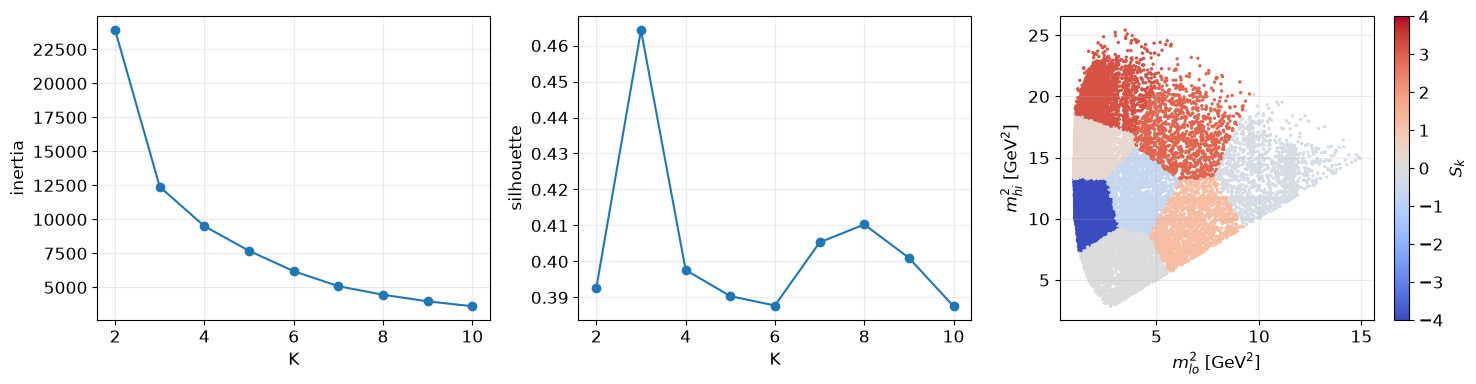

In [18]:
Ks = range(2, 11)
inertia, sil = [], []
sub = np.random.choice(len(Z), 4000, replace=False)
for K in Ks:
    kmk = KMeans(n_clusters=K, n_init=5, random_state=SEED).fit(Z)
    inertia.append(kmk.inertia_); sil.append(silhouette_score(Z[sub], kmk.labels_[sub]))
km2 = KMeans(n_clusters=8, n_init=10, random_state=7).fit(Z)
print(f"adjusted Rand index between two seeds (K = 8): {adjusted_rand_score(km.labels_, km2.labels_):.3f}   (report: > 0.998)")
print(f"silhouette maximum at K = {list(Ks)[int(np.argmax(sil))]}   (report: K = 3)")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(list(Ks), inertia, "o-"); ax[0].set(xlabel="K", ylabel="inertia")
ax[1].plot(list(Ks), sil, "o-"); ax[1].set(xlabel="K", ylabel="silhouette")
sc_ = ax[2].scatter(lo2, hi2, c=cl.S.values[km.labels_], s=2, cmap="coolwarm", vmin=-4, vmax=4)
plt.colorbar(sc_, ax=ax[2], label="$S_k$"); ax[2].set(xlabel="$m^2_{lo}$ [GeV$^2$]", ylabel="$m^2_{hi}$ [GeV$^2$]")
plt.tight_layout(); plt.show()

## 8 · A high-background sample: where an ML selection could really help

In the nominal sample the background under the peak is small and the ML selection does not improve $\sigma(A)$.
Starting from a *looser* PID selection ($\texttt{ProbK}>0.3$, much more background) we compare two ways of cleaning it
**at equal signal efficiency**: tightening the PID cut ($\texttt{ProbK}>0.4,\dots,0.8$) or cutting on the score of the
classifier retrained on the weak labels of this sample (same features and hyperparameters).
Signal efficiency is $N_s$ of the fit relative to $N_s$ of the loose sample.

loose sample: 33328 candidates, A = -0.0552 +- 0.0072, N_s = 22593


selection    cut  signal_eff       A  sigma_A
  PID cut 0.4000      0.8594 -0.0473   0.0076
  PID cut 0.5000      0.6785 -0.0441   0.0085
  PID cut 0.6000      0.4975 -0.0383   0.0098
  PID cut 0.7000      0.3165 -0.0553   0.0123
  PID cut 0.8000      0.1781 -0.0431   0.0163
score cut 0.3000      0.9804 -0.0560   0.0070
score cut 0.5000      0.9253 -0.0552   0.0071
score cut 0.7000      0.7741 -0.0541   0.0077
score cut 0.8000      0.5882 -0.0464   0.0088
score cut 0.9000      0.2097 -0.0536   0.0147


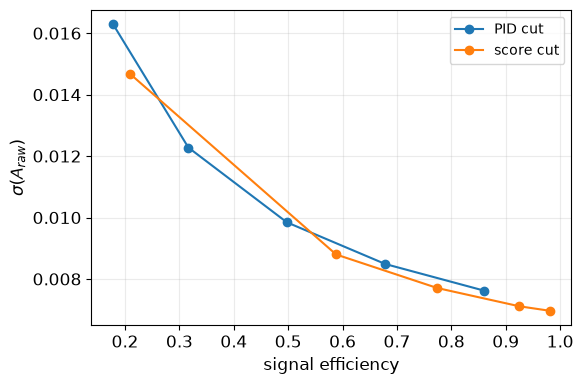

report: at equal signal efficiency the two cleanings give about the same sigma(A); the ML selection brings little over tightening the PID cut


In [19]:
loose = d.copy()                                              # ProbK > 0.3, all candidates in the window
fit_loose = fit_asymmetry(loose)
Ns_ref = fit_loose.values["N_s"]
print(f"loose sample: {len(loose)} candidates, A = {fit_loose.values['A']:+.4f} +- {fit_loose.errors['A']:.4f}, N_s = {Ns_ref:.0f}")

ml = loose.m.to_numpy()
sig_l = np.abs(ml - MU) < 2 * SIGMA
bkg_l = ((ml >= 5150) & (ml < MU - 4 * SIGMA)) | ((ml > MU + 4 * SIGMA) & (ml <= HI))
lab_l = loose[sig_l | bkg_l]
y_l = sig_l[sig_l | bkg_l].astype(int)
sw_l = np.where(y_l == 1, len(y_l) / (2 * y_l.sum()), len(y_l) / (2 * (len(y_l) - y_l.sum())))
gbm_l = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED)
gbm_l.fit(lab_l[FEATURES].to_numpy(), y_l, sample_weight=sw_l)
loose = loose.assign(score=gbm_l.predict_proba(loose[FEATURES].to_numpy())[:, 1])

rows = []
for k in (0.4, 0.5, 0.6, 0.7, 0.8):
    f = fit_asymmetry(loose[loose.min_probk > k])
    rows.append(("PID cut", k, f.values["N_s"] / Ns_ref, f.values["A"], f.errors["A"]))
for t in (0.3, 0.5, 0.7, 0.8, 0.9):
    f = fit_asymmetry(loose[loose.score > t])
    rows.append(("score cut", t, f.values["N_s"] / Ns_ref, f.values["A"], f.errors["A"]))
hb = pd.DataFrame(rows, columns=["selection", "cut", "signal_eff", "A", "sigma_A"])
print(hb.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
fig, ax = plt.subplots(figsize=(6, 4))
for sel_name, g in hb.groupby("selection"):
    ax.plot(g.signal_eff, g.sigma_A, "o-", label=sel_name)
ax.set(xlabel="signal efficiency", ylabel="$\\sigma(A_{raw})$"); ax.legend(); plt.tight_layout(); plt.show()
print("report: at equal signal efficiency the two cleanings give about the same sigma(A); "
      "the ML selection brings little over tightening the PID cut")

## 9 · Summary

1. **Weak labels** from the mass spectrum (CWoLa) allow a signal/background classifier without true labels, provided
   the mass is not a feature; the classes are imbalanced and are balanced with class weights.
2. **Tree ensembles and the FFNN** are indistinguishable (test AUC $\approx0.86$) and $\approx0.09$ above the linear
   models; gradient boosting is the reference. Ridge and Lasso reach the same AUC: the linear model is limited by its
   decision boundary, not by variance. Gradient boosting overfits beyond ~150 stages without gain.
3. **Class weights bias the probabilities**; an isotonic recalibration corrects it without changing the ranking.
4. The **uncertainty estimators** measure different things; only the forest spread decreases clearly with more data.
5. **Hyperparameter search** brings no significant gain (winner's curse).
6. A cut on the score leaves $A_{\rm raw}$ **unchanged** within its statistical spread and does not improve its precision;
   the worsened mass fit is a change of the background composition, not sculpting.
7. **$K$-means** on the Dalitz plane finds the same local pattern as the fixed grid.

In [20]:
print(f"Total running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Total running time of this notebook: 9.4 min
